# RSNA Knee Abnormality Detection — Dataset Exploration

This notebook explores the dataset provided by the **RSNA Knee Abnormality Detection** competition on Kaggle.

The dataset is loaded from the competition dataset attached through the **Input** panel on the right side of the Kaggle notebook.

The exploration covers:
- Dataset structure, dimensions, and data types
- Gold cases with all 12 human-provided labels
- Label distributions among gold cases
- Radiology reports and their languages
- MRI series metadata and image visualization

In [ ]:
!git clone https://github.com/saloni644c/knee-abnormality.git

In [ ]:
import sys
sys.path.insert(0, "/kaggle/working/RSNA-Knee")

from src.data import (
    TARGET_COLUMNS,
    load_training_data,
    load_test_data,
    get_gold_cases,
    get_study_index,
    get_study_report,
    get_study_labels,
    get_study_series,
    get_mri_files,
)

In [6]:
from pathlib import Path

DATA_ROOT = Path(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection"
)

DATA_FILE = Path("/kaggle/working/RSNA-Knee/src/data.py")

print("Dataset exists:", DATA_ROOT.exists())
print("data.py exists:", DATA_FILE.exists())

Dataset exists: True
data.py exists: True


In [11]:
import sys

sys.path.insert(0, "/kaggle/working/RSNA-Knee")

from src.data import (
    TARGET_COLUMNS,
    load_training_data,
    load_test_data,
    get_gold_cases,
    get_study_index,
    get_study_report,
    get_study_labels,
    get_study_series,
    get_mri_files,
)

print("All functions imported successfully.")

All functions imported successfully.


In [12]:
train_df, train_series_df = load_training_data(DATA_ROOT)
test_df, test_series_df = load_test_data(DATA_ROOT)

print("Training studies:", train_df.shape)
print("Training series:", train_series_df.shape)
print("Test studies:", test_df.shape)
print("Test series:", test_series_df.shape)

Training studies: (4407, 14)
Training series: (24371, 5)
Test studies: (3, 1)
Test series: (15, 5)


In [13]:
gold_df = get_gold_cases(train_df)

print("Total training studies:", len(train_df))
print("Gold cases:", len(gold_df))
print("Gold cases with missing target labels:",
      gold_df[TARGET_COLUMNS].isna().any(axis=1).sum())

display(gold_df.head())

Total training studies: 4407
Gold cases: 58
Gold cases with missing target labels: 0


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,Antecedentes Clínicos:\nEsguince rodilla. [DAT...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.2.826.0.1.3680043.8.498.10170898615867673028...,The study reveals normal knee joint alignment...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.10306159113324811538...,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Da...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,1.2.826.0.1.3680043.8.498.11287937729196958426...,"MRI of left Knee with \n-3-Plane Loc R'T, Sag ...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,1.2.826.0.1.3680043.8.498.11382021393803389951...,"In the medial compartment, there is longitudi...",1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
study_id = gold_df.iloc[0]["StudyInstanceUID"]

study_index = get_study_index(train_df)
report = get_study_report(train_df, study_id)
labels = get_study_labels(train_df, study_id)
series = get_study_series(train_series_df, study_id)

print("Study ID:", study_id)
print("Study found in index:", study_id in study_index.index)
print("\nReport:")
print(report)
print("\nLabels:")
print(labels)
print("\nMRI series:")
display(series)

Study ID: 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Study found in index: True

Report:
Antecedentes Clínicos:
Esguince rodilla. [DATE].
Hallazgos:
No hay alteraciones de señal significativas de la médula ósea.
Ligamentos cruzados y colaterales dentro de límites normales.
Amputación marginal del cuerpo del menisco lateral. Menisco medial de morfología y señal
conservada, sin signos de rotura.
Cartílagos de los compartimentos femorotibiales sin alteraciones.
Fina úlcera condral focal de espesor total del aspecto inferior de la vertiente medial de la tróclea
femoral con mínimos cambios óseos secundarios. Fenómenos condrales reparativos de la región
central de la simple femoral. Cartílago rotuliano sin alteraciones.
Leve derrame articular. No hay quistes poplíteos patológicos.
Aumento de señal de la inserción distal del tendón cuadricipital y de la inserción proximal del
tendón rotuliano, sin signos de rotura.
No hay alteraciones de señal de la grasa de Hoffa.
Impre

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
163,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.10791858932231443712...,0,0,Sagittal
164,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.12451507871565834868...,0,0,Coronal
165,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.21497837050858589852...,1,1,Coronal
166,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,1,1,Sagittal
167,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,1,1,Axial


In [14]:
series_row = series.iloc[0]

mri_files = get_mri_files(
    DATA_ROOT,
    study_id,
    series_id=series_row["SeriesInstanceUID"],
)

print("MRI files found:", len(mri_files))
print("First MRI file:", mri_files[0] if mri_files else "None")

MRI files found: 36
First MRI file: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149/1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282/1.2.826.0.1.3680043.8.498.10418337450088796288331730319855216339.dcm


In [15]:
# Display dataset dimensions

dataset_summary = pd.DataFrame({
    "Dataset": [
        "Training studies",
        "Test studies",
        "Training MRI series",
        "Test MRI series",
        "Gold cases",
    ],
    "Number of records": [
        len(train_df),
        len(test_df),
        len(train_series_df),
        len(test_series_df),
        len(gold_df),
    ],
})

display(dataset_summary)

,Dataset,Number of records
0,Training studies,4407
1,Test studies,3
2,Training MRI series,24371
3,Test MRI series,15
4,Gold cases,58


In [16]:
# Inspect the training dataset schema

schema_df = pd.DataFrame({
    "Column": train_df.columns,
    "Data Type": train_df.dtypes.astype(str).values,
    "Missing Values": train_df.isna().sum().values,
    "Missing (%)": (
        train_df.isna().mean().values * 100
    ).round(2),
    "Unique Values": train_df.nunique().values,
})

display(schema_df)

,Column,Data Type,Missing Values,Missing (%),Unique Values
0,StudyInstanceUID,object,0,0.00,4407
1,Report,object,0,0.00,4276
2,ACL,float64,4349,98.68,2
3,MCL,float64,4349,98.68,2
4,Medial Meniscus,float64,4349,98.68,2
5,Lateral Meniscus,float64,4349,98.68,2
6,Medial OA,float64,4349,98.68,2
7,Lateral OA,float64,4349,98.68,2
8,PF OA,float64,4349,98.68,2
9,Effusion,float64,4349,98.68,2


In [17]:
# Inspect MRI series metadata

series_schema_df = pd.DataFrame({
    "Column": train_series_df.columns,
    "Data Type": train_series_df.dtypes.astype(str).values,
    "Missing Values": train_series_df.isna().sum().values,
    "Missing (%)": (
        train_series_df.isna().mean().values * 100
    ).round(2),
    "Unique Values": train_series_df.nunique().values,
})

display(series_schema_df)

,Column,Data Type,Missing Values,Missing (%),Unique Values
0,StudyInstanceUID,object,0,0.0,4407
1,SeriesInstanceUID,object,0,0.0,24371
2,Fluid_Sensitive,int64,0,0.0,2
3,Fat_Suppression,int64,0,0.0,2
4,Anatomical_Plane,object,0,0.0,3


In [20]:
# Count positive and negative labels in gold cases only

label_summary = pd.DataFrame({
    "Finding": TARGET_COLUMNS,
    "Positive (1)": [
        (gold_df[col] == 1).sum()
        for col in TARGET_COLUMNS
    ],
    "Negative (0)": [
        (gold_df[col] == 0).sum()
        for col in TARGET_COLUMNS
    ],
})

display(label_summary)

,Finding,Positive (1),Negative (0)
0,ACL,24,34
1,MCL,9,49
2,Medial Meniscus,26,32
3,Lateral Meniscus,23,35
4,Medial OA,15,43
5,Lateral OA,11,47
6,PF OA,21,37
7,Effusion,35,23
8,Synovitis,27,31
9,Baker's,12,46


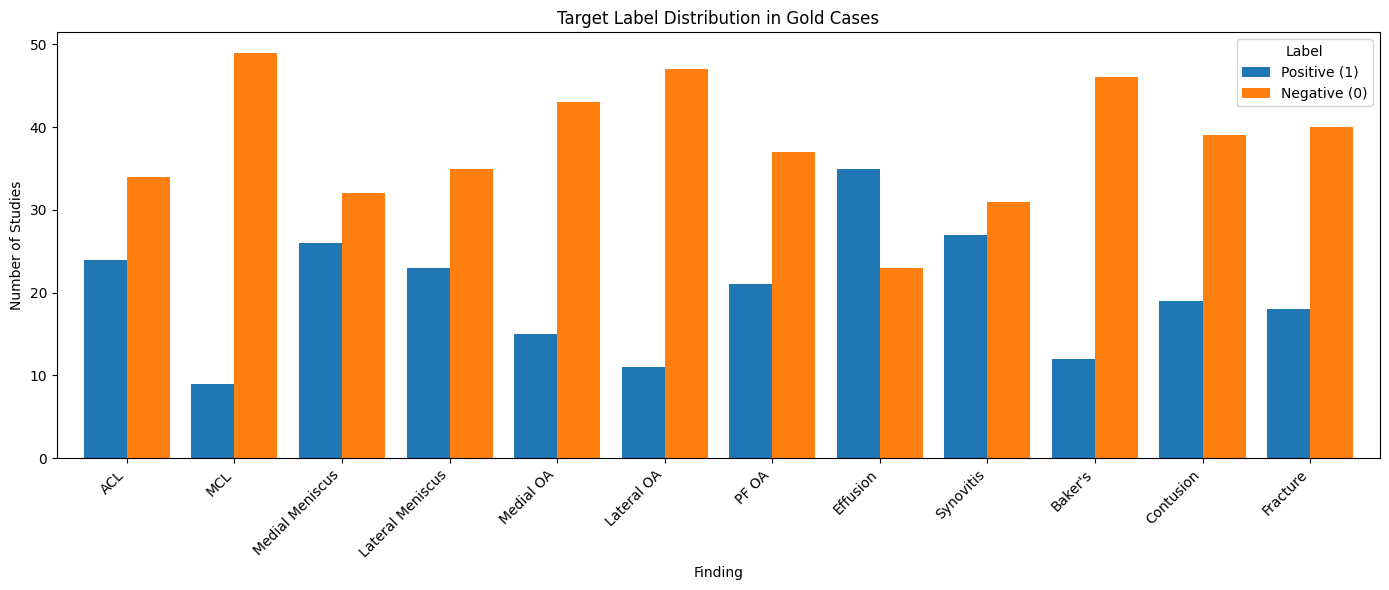

In [21]:
label_summary.set_index("Finding")[
    ["Positive (1)", "Negative (0)"]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Target Label Distribution in Gold Cases")
plt.xlabel("Finding")
plt.ylabel("Number of Studies")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Label")
plt.tight_layout()
plt.show()

In [22]:
print("Total training studies:", len(train_df))
print("Gold cases:", len(gold_df))

assert gold_df[TARGET_COLUMNS].notna().all().all(), (
    "Gold cases contain missing target labels."
)

print("Verified: all gold cases have all 12 target labels.")

Total training studies: 4407
Gold cases: 58
Verified: all gold cases have all 12 target labels.


Study ID: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
Series ID: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Number of MRI slices: 22


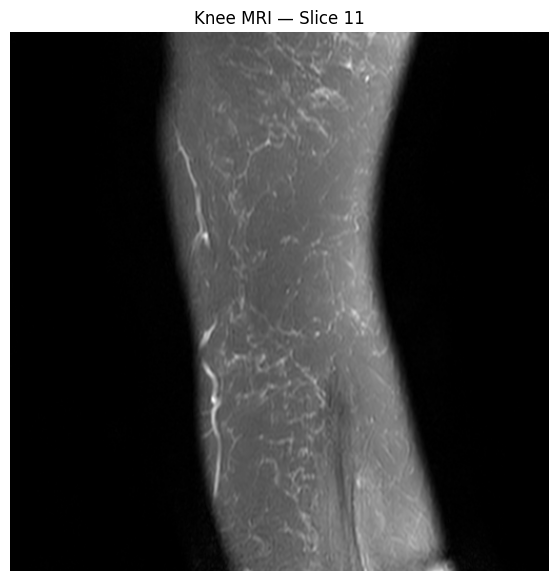

In [23]:
import matplotlib.pyplot as plt
import pydicom

# Select a study and its MRI series
study_id = train_df.iloc[0]["StudyInstanceUID"]
series = get_study_series(train_series_df, study_id)

series_id = series.iloc[0]["SeriesInstanceUID"]

# Find MRI DICOM files
mri_files = get_mri_files(DATA_ROOT, study_id, series_id)

print(f"Study ID: {study_id}")
print(f"Series ID: {series_id}")
print(f"Number of MRI slices: {len(mri_files)}")

# Display the middle slice
if mri_files:
    middle_file = mri_files[len(mri_files) // 2]
    dicom = pydicom.dcmread(str(middle_file))

    plt.figure(figsize=(7, 7))
    plt.imshow(dicom.pixel_array, cmap="gray")
    plt.title(f"Knee MRI — Slice {len(mri_files) // 2}")
    plt.axis("off")
    plt.show()
else:
    print("No MRI slices found for this study and series.")